# Chapter 2 — Cơ sở lý thuyết của Diffusion Map

---
## 2.1. Thiết lập toán học

Cho tập dữ liệu $\mathcal{X}=\{x_1,x_2,\ldots,x_n\}\subset\mathbb{R}^d$ được lấy mẫu từ đa tạp $\mathcal{M}$ có số chiều nội tại $m\ll d$.

**Diffusion Maps** xây dựng biểu diễn giảm chiều dựa trên cấu trúc liên kết nội tại của đa tạp. Đối với đa tạp cong, khoảng cách Euclid $d_E(x_i,x_j)$ không nhất thiết phản ánh đúng khoảng cách trắc địa $d_{\mathcal{M}}(x_i,x_j)$.

Hình bên dưới minh họa đặc điểm này trên bộ dữ liệu **Swiss Roll**:

- **(A)** Sự khác biệt giữa khoảng cách Euclid và khoảng cách trắc địa.
- **(B)** Xấp xỉ khoảng cách trắc địa thông qua đồ thị lân cận.
- **(C)** Biểu diễn giảm chiều bằng phương pháp Isomap.

Nguồn: Tenenbaum và cộng sự (2000).

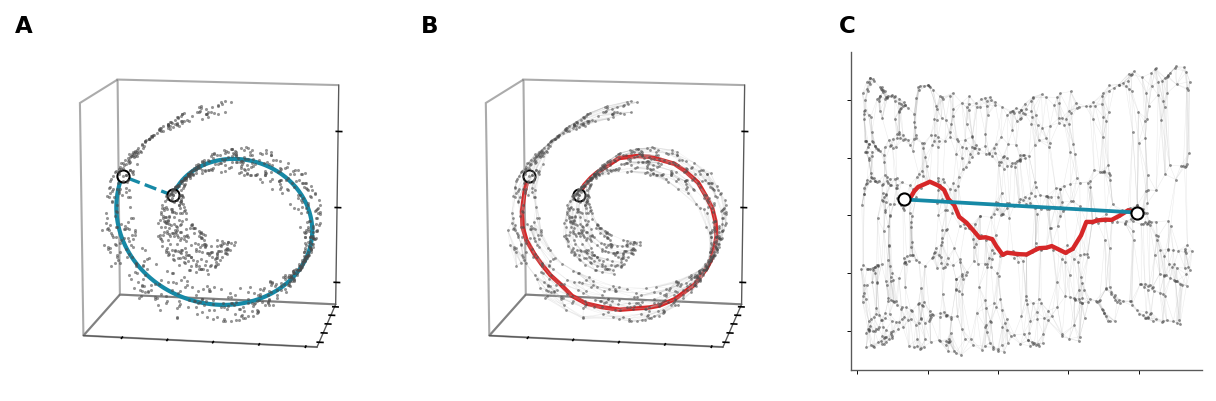

Saved: /content/pictures/fig2_1_manifold_setting.pdf


In [13]:
import os
import numpy as np
import matplotlib.pyplot as plt

from matplotlib.collections import LineCollection
from mpl_toolkits.mplot3d.art3d import Line3DCollection
from scipy.sparse.csgraph import dijkstra
from sklearn.datasets import make_swiss_roll
from sklearn.manifold import Isomap
from sklearn.neighbors import kneighbors_graph


# ============================================================
# 1. Swiss Roll data
# ============================================================

N = 1000
K = 7

X, t = make_swiss_roll(
    n_samples=N,
    noise=0.05,
    random_state=42
)

height = X[:, 1]


# ============================================================
# 2. Select two points on adjacent folds
# ============================================================

target_t = t.min() + 0.22 * np.ptp(t)
target_h = np.median(height)

score_a = ((t - target_t) / 0.30)**2 + ((height - target_h) / 1.00)**2
point_a = int(np.argmin(score_a))

target_t_b = t[point_a] + 2.0 * np.pi
score_b = ((t - target_t_b) / 0.30)**2 + ((height - height[point_a]) / 1.00)**2
point_b = int(np.argmin(score_b))


# ============================================================
# 3. k-NN graph and shortest path
# ============================================================

graph = kneighbors_graph(
    X,
    n_neighbors=K,
    mode="distance",
    include_self=False
)

graph = graph.maximum(graph.T).tocsr()

graph_distance, predecessors = dijkstra(
    graph,
    directed=False,
    indices=point_a,
    return_predecessors=True
)

if not np.isfinite(graph_distance[point_b]):
    raise RuntimeError("Đồ thị không liên thông. Hãy tăng K lên 8 hoặc 9.")

path_indices = [point_b]

while path_indices[-1] != point_a:
    previous = int(predecessors[path_indices[-1]])

    if previous < 0:
        raise RuntimeError("Không tìm được đường đi giữa hai điểm.")

    path_indices.append(previous)

path_indices = np.asarray(path_indices[::-1])
graph_path = X[path_indices]


# ============================================================
# 4. Smooth path along the Swiss Roll manifold
# ============================================================

t_path = np.linspace(
    t[point_a],
    t[point_b],
    300
)

h_path = np.linspace(
    height[point_a],
    height[point_b],
    300
)

manifold_path = np.column_stack([
    t_path * np.cos(t_path),
    h_path,
    t_path * np.sin(t_path)
])

manifold_path[0] = X[point_a]
manifold_path[-1] = X[point_b]


# ============================================================
# 5. Isomap embedding
# ============================================================

isomap = Isomap(
    n_neighbors=K,
    n_components=2,
    eigen_solver="arpack",
    path_method="D"
)

X_iso = isomap.fit_transform(X)
X_iso = X_iso - X_iso.mean(axis=0)

# Keep the longest Isomap direction horizontal.
if np.ptp(X_iso[:, 0]) < np.ptp(X_iso[:, 1]):
    X_iso = X_iso[:, [1, 0]]

# Place point A on the left and point B on the right.
if X_iso[point_a, 0] > X_iso[point_b, 0]:
    X_iso[:, 0] *= -1


# ============================================================
# 6. Graph edges
# ============================================================

graph_coo = graph.tocoo()
unique_edges = graph_coo.row < graph_coo.col
edge_rows = graph_coo.row[unique_edges]
edge_cols = graph_coo.col[unique_edges]

segments_3d = np.stack([
    X[edge_rows],
    X[edge_cols]
], axis=1)

segments_2d = np.stack([
    X_iso[edge_rows],
    X_iso[edge_cols]
], axis=1)


# ============================================================
# 7. Figure
# ============================================================

BLUE = "#1689A6"
RED = "#D62728"
POINT_COLOR = "#4A4A4A"
EDGE_COLOR = "#B8B8B8"

fig = plt.figure(figsize=(8.2, 2.75))

panel_a = [0.020, 0.090, 0.295, 0.840]
panel_b = [0.350, 0.090, 0.295, 0.840]
panel_c = [0.690, 0.130, 0.285, 0.770]

ax_a = fig.add_axes(
    panel_a,
    projection="3d"
)

ax_b = fig.add_axes(
    panel_b,
    projection="3d"
)

ax_c = fig.add_axes(panel_c)


# ============================================================
# Panel A: Euclidean and manifold paths
# ============================================================

ax_a.scatter(
    X[:, 0],
    X[:, 1],
    X[:, 2],
    color=POINT_COLOR,
    s=2.2,
    alpha=0.58,
    linewidths=0,
    depthshade=False,
    rasterized=True
)

ax_a.plot(
    manifold_path[:, 0],
    manifold_path[:, 1],
    manifold_path[:, 2],
    color=BLUE,
    linewidth=2.0
)

ax_a.plot(
    X[[point_a, point_b], 0],
    X[[point_a, point_b], 1],
    X[[point_a, point_b], 2],
    color=BLUE,
    linestyle="--",
    linewidth=1.6
)

ax_a.scatter(
    X[[point_a, point_b], 0],
    X[[point_a, point_b], 1],
    X[[point_a, point_b], 2],
    s=34,
    facecolors="white",
    edgecolors="black",
    linewidths=1.0,
    depthshade=False
)


# ============================================================
# Panel B: k-NN shortest path
# ============================================================

edges_3d = Line3DCollection(
    segments_3d,
    colors=EDGE_COLOR,
    linewidths=0.24,
    alpha=0.24
)

edges_3d.set_rasterized(True)
ax_b.add_collection3d(edges_3d)

ax_b.scatter(
    X[:, 0],
    X[:, 1],
    X[:, 2],
    color=POINT_COLOR,
    s=1.8,
    alpha=0.58,
    linewidths=0,
    depthshade=False,
    rasterized=True
)

ax_b.plot(
    graph_path[:, 0],
    graph_path[:, 1],
    graph_path[:, 2],
    color=RED,
    linewidth=2.1
)

ax_b.scatter(
    X[[point_a, point_b], 0],
    X[[point_a, point_b], 1],
    X[[point_a, point_b], 2],
    s=34,
    facecolors="white",
    edgecolors="black",
    linewidths=1.0,
    depthshade=False
)


# ============================================================
# Panel C: Isomap embedding
# ============================================================

edges_2d = LineCollection(
    segments_2d,
    colors=EDGE_COLOR,
    linewidths=0.24,
    alpha=0.30,
    zorder=1
)

edges_2d.set_rasterized(True)
ax_c.add_collection(edges_2d)

ax_c.scatter(
    X_iso[:, 0],
    X_iso[:, 1],
    color=POINT_COLOR,
    s=1.8,
    alpha=0.62,
    linewidths=0,
    rasterized=True,
    zorder=2
)

ax_c.plot(
    X_iso[path_indices, 0],
    X_iso[path_indices, 1],
    color=RED,
    linewidth=2.1,
    zorder=4
)

ax_c.plot(
    X_iso[[point_a, point_b], 0],
    X_iso[[point_a, point_b], 1],
    color=BLUE,
    linewidth=1.8,
    zorder=5
)

ax_c.scatter(
    X_iso[[point_a, point_b], 0],
    X_iso[[point_a, point_b], 1],
    s=34,
    facecolors="white",
    edgecolors="black",
    linewidths=1.0,
    zorder=6
)


# ============================================================
# 8. Clean formatting
# ============================================================

for ax in [ax_a, ax_b]:
    try:
        ax.set_box_aspect(
            (1.0, 0.70, 1.0),
            zoom=1.02
        )
    except TypeError:
        ax.set_box_aspect((1.0, 0.70, 1.0))

    # Look almost directly along the height direction.
    ax.view_init(
        elev=12,
        azim=100
    )

    ax.grid(False)
    ax.set_xticklabels([])
    ax.set_yticklabels([])
    ax.set_zticklabels([])
    ax.tick_params(length=2, width=0.45, pad=-2)

    for axis in [
        ax.xaxis,
        ax.yaxis,
        ax.zaxis
    ]:
        axis.pane.fill = False
        axis.pane.set_edgecolor("0.35")
        axis.line.set_color("0.35")
        axis.line.set_linewidth(0.65)

# Do not use equal aspect here; it would flatten panel C.
x_margin = 0.03 * np.ptp(X_iso[:, 0])
y_margin = 0.05 * np.ptp(X_iso[:, 1])

ax_c.set_xlim(
    X_iso[:, 0].min() - x_margin,
    X_iso[:, 0].max() + x_margin
)

ax_c.set_ylim(
    X_iso[:, 1].min() - y_margin,
    X_iso[:, 1].max() + y_margin
)

ax_c.set_aspect("auto")
ax_c.tick_params(labelbottom=False, labelleft=False, length=2, width=0.45)
ax_c.spines["top"].set_visible(False)
ax_c.spines["right"].set_visible(False)
ax_c.spines["left"].set_color("0.35")
ax_c.spines["bottom"].set_color("0.35")
ax_c.spines["left"].set_linewidth(0.65)
ax_c.spines["bottom"].set_linewidth(0.65)

fig.text(0.010, 0.935, "A", ha="left", va="bottom", fontsize=11, fontweight="bold")
fig.text(0.340, 0.935, "B", ha="left", va="bottom", fontsize=11, fontweight="bold")
fig.text(0.680, 0.935, "C", ha="left", va="bottom", fontsize=11, fontweight="bold")


# ============================================================
# 9. Save
# ============================================================

output_directory = "/content/pictures"
os.makedirs(output_directory, exist_ok=True)

pdf_path = os.path.join(
    output_directory,
    "fig2_1_manifold_setting.pdf"
)

fig.savefig(
    pdf_path,
    dpi=600,
    bbox_inches=None,
    pad_inches=0
)

plt.show()

print("Saved:", pdf_path)

---
## 2.2. Xây dựng đồ thị tương đồng dựa trên hàm nhân

Xét đồ thị có trọng số $G=(V,E,W)$, trong đó mỗi đỉnh tương ứng với một điểm dữ liệu. Ma trận tương đồng $W$ được xác định thông qua hàm nhân Gaussian:

$$
W_{ij}=\exp\left(-\frac{\|x_i-x_j\|_2^2}{\varepsilon}\right),
\quad \varepsilon>0.
$$

Tham số độ rộng $\varepsilon$ kiểm soát phạm vi lân cận giữa các điểm dữ liệu. Khi $\varepsilon$ quá nhỏ, tính liên kết của đồ thị suy giảm. Khi $\varepsilon$ quá lớn, các trọng số có xu hướng đồng nhất, làm mờ cấu trúc hình học cục bộ. Giá trị tham chiếu được xác định bởi:

$$
\varepsilon_{\mathrm{med}}=\operatorname{median}
\left\{\|x_i-x_j\|_2^2:\;1\leq i<j\leq n\right\}.
$$

Hình minh họa bên dưới thể hiện ảnh hưởng của $\varepsilon$ đến cấu trúc tương đồng của dữ liệu.

### Chuẩn hóa theo mật độ

Để giảm ảnh hưởng của mật độ lấy mẫu không đồng đều, ma trận tương đồng được chuẩn hóa như sau:

$$
q_i=\sum_{j=1}^{n}W_{ij},
\qquad
\widetilde{W}_{ij}=\frac{W_{ij}}{q_i^\alpha q_j^\alpha},
\quad \alpha\in[0,1].
$$

Tham số $\alpha$ kiểm soát mức độ hiệu chỉnh mật độ. Khi $\alpha=0$, ma trận tương đồng được giữ nguyên. Khi $\alpha=1$, ảnh hưởng của mật độ lấy mẫu được loại bỏ trong giới hạn tiệm cận dưới các giả thiết thích hợp.

Kết quả minh họa bên dưới thể hiện ảnh hưởng của quá trình chuẩn hóa đối với dữ liệu có mật độ lấy mẫu không đồng đều.

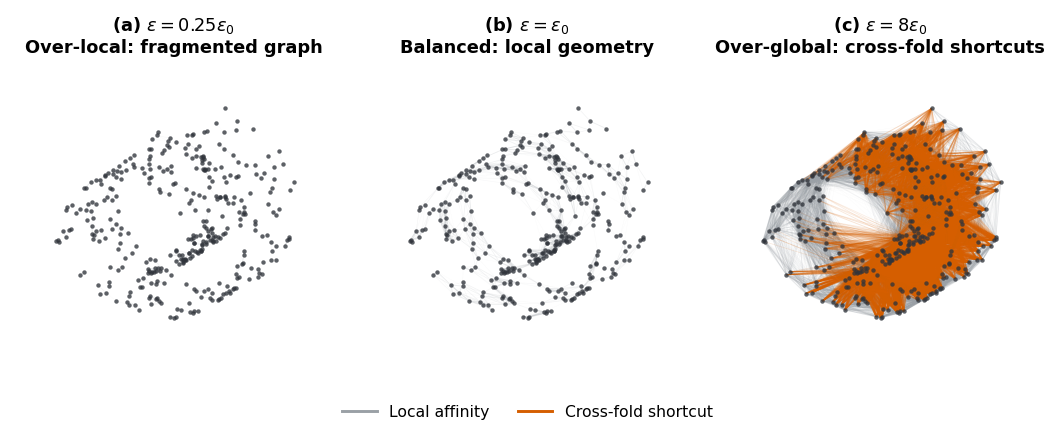

Saved: /content/pictures/fig2_2_epsilon_sensitivity_swiss_roll.pdf


In [14]:

# ── Figure 2.2 — Bandwidth sensitivity on Swiss Roll ───────────────────────
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

from matplotlib.lines import Line2D
from mpl_toolkits.mplot3d.art3d import Line3DCollection
from scipy.spatial.distance import cdist
from sklearn.datasets import make_swiss_roll
from sklearn.neighbors import NearestNeighbors

# ── 1. Swiss Roll data ──────────────────────────────────────────────────────
N = 360
K_REF = 7
X, t = make_swiss_roll(n_samples=N, noise=0.10, random_state=42)

# ── 2. Reference bandwidth from local k-NN distances ───────────────────────
D2 = cdist(X, X, metric='sqeuclidean')
knn_dist, _ = NearestNeighbors(n_neighbors=K_REF + 1).fit(X).kneighbors(X)
epsilon_0 = float(np.median(knn_dist[:, K_REF] ** 2))

epsilon_factors = [0.25, 1.00, 8.00]
epsilon_values = [factor * epsilon_0 for factor in epsilon_factors]
W_THRESHOLD = 0.30

panel_titles = [r'(a) $\varepsilon=0.25\varepsilon_0$' + '\nOver-local: fragmented graph', r'(b) $\varepsilon=\varepsilon_0$' + '\nBalanced: local geometry', r'(c) $\varepsilon=8\varepsilon_0$' + '\nOver-global: cross-fold shortcuts']

POINT_COLOR = '#30343B'
LOCAL_COLOR = '#9AA0A6'
SHORTCUT_COLOR = '#D55E00'

# ── 3. Draw weighted graph edges ────────────────────────────────────────────
def add_weighted_edges(ax, segments, weights, color, alpha_min, alpha_max, width_min, width_max):
    if len(segments) == 0:
        return
    strength = np.clip((weights - W_THRESHOLD) / (1.0 - W_THRESHOLD), 0.0, 1.0)
    rgba = np.tile(mcolors.to_rgba(color), (len(weights), 1))
    rgba[:, 3] = alpha_min + strength * (alpha_max - alpha_min)
    widths = width_min + strength * (width_max - width_min)
    collection = Line3DCollection(segments, colors=rgba, linewidths=widths, rasterized=True)
    ax.add_collection3d(collection)

# ── 4. Common limits for equal-sized panels ─────────────────────────────────
padding = 0.6
x_lim = (X[:, 0].min() - padding, X[:, 0].max() + padding)
y_lim = (X[:, 1].min() - padding, X[:, 1].max() + padding)
z_lim = (X[:, 2].min() - padding, X[:, 2].max() + padding)

# ── 5. Figure layout ─────────────────────────────────────────────────────────
fig = plt.figure(figsize=(7.2, 2.75))
panel_positions = [[0.015, 0.15, 0.315, 0.77], [0.342, 0.15, 0.315, 0.77], [0.669, 0.15, 0.315, 0.77]]

for position, epsilon, title in zip(panel_positions, epsilon_values, panel_titles):
    ax = fig.add_axes(position, projection='3d')
    W = np.exp(-D2 / epsilon)
    np.fill_diagonal(W, 0.0)
    edge_mask = np.triu(W >= W_THRESHOLD, k=1)
    row, col = np.where(edge_mask)
    edge_weights = W[row, col]
    edge_segments = np.stack([X[row], X[col]], axis=1)
    shortcut_mask = np.abs(t[row] - t[col]) > np.pi

    add_weighted_edges(ax, edge_segments[~shortcut_mask], edge_weights[~shortcut_mask], LOCAL_COLOR, 0.04, 0.28, 0.18, 0.60)
    add_weighted_edges(ax, edge_segments[shortcut_mask], edge_weights[shortcut_mask], SHORTCUT_COLOR, 0.12, 0.65, 0.35, 1.10)

    ax.scatter(X[:, 0], X[:, 1], X[:, 2], c=POINT_COLOR, s=4.5, alpha=0.78, linewidths=0, depthshade=False, rasterized=True)
    ax.set_xlim(x_lim)
    ax.set_ylim(y_lim)
    ax.set_zlim(z_lim)
    ax.set_box_aspect((1.08, 0.72, 1.00))
    ax.view_init(elev=18, azim=-64)
    ax.set_proj_type('ortho')
    ax.set_axis_off()
    ax.set_title(title, fontsize=8.5, fontweight='bold', pad=1.5)

# ── 6. Shared legend ─────────────────────────────────────────────────────────
legend_handles = [Line2D([0], [0], color=LOCAL_COLOR, linewidth=1.4, label='Local affinity'), Line2D([0], [0], color=SHORTCUT_COLOR, linewidth=1.4, label='Cross-fold shortcut')]
fig.legend(handles=legend_handles, loc='lower center', bbox_to_anchor=(0.5, 0.005), ncol=2, frameon=False, fontsize=7.5, handlelength=2.2, columnspacing=1.8)

# ── 7. Save PDF ──────────────────────────────────────────────────────────────
output_dir = '/content/pictures'
os.makedirs(output_dir, exist_ok=True)
output_file = os.path.join(output_dir, 'fig2_2_epsilon_sensitivity_swiss_roll.pdf')
fig.savefig(output_file, dpi=600, bbox_inches='tight', pad_inches=0.03)
plt.show()

print(f'Saved: {output_file}')


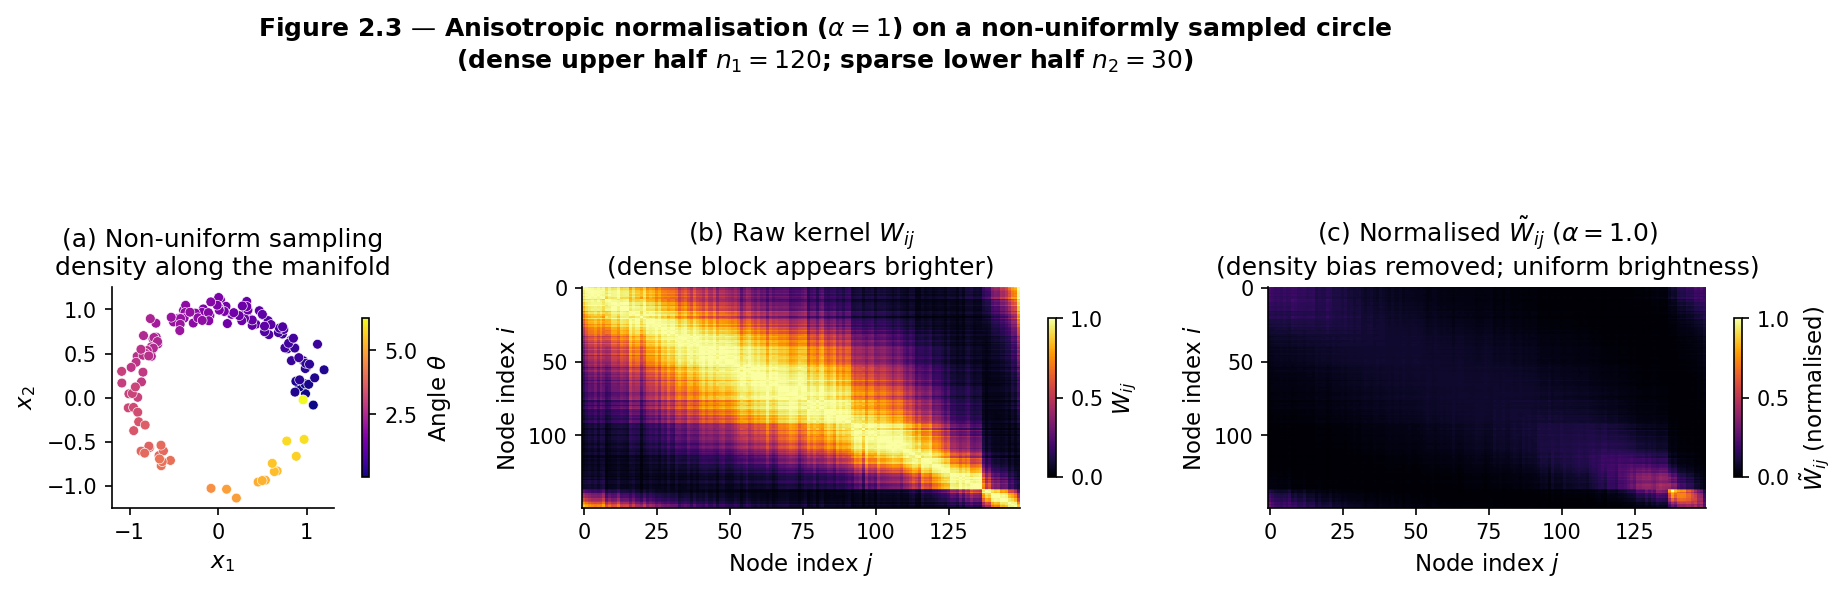

Saved: fig2_3_anisotropic_normalisation.pdf


In [ ]:
# ── Figure 2.3 — Anisotropic normalisation on a non-uniform circle ──────────
np.random.seed(2)
# Non-uniform sampling: dense upper semicircle, sparse lower semicircle
theta_d = np.random.uniform(0, np.pi,      120)   # dense top
theta_s = np.random.uniform(np.pi, 2*np.pi, 30)   # sparse bottom
theta_all = np.concatenate([theta_d, theta_s])
idx_s = np.argsort(theta_all)
theta_all = theta_all[idx_s]                        # sorted by angle

X_nu = (np.column_stack([np.cos(theta_all), np.sin(theta_all)])
        + np.random.randn(150, 2) * 0.07)

D2_nu  = cdist(X_nu, X_nu, 'sqeuclidean')
eps_nu = float(np.median(D2_nu[D2_nu > 0]))
W_raw  = np.exp(-D2_nu / eps_nu)

# α = 1 normalisation
q       = W_raw.sum(axis=1)
alpha_d = 1.0
W_tilde = W_raw / np.outer(q**alpha_d, q**alpha_d)
W_tn    = W_tilde / W_tilde.max()   # rescale to [0,1] for display

fig, axes = plt.subplots(1, 3, figsize=(14, 4.0))
fig.suptitle(
    r'Figure 2.3 — Anisotropic normalisation ($\alpha = 1$) on a non-uniformly sampled circle'
    '\n(dense upper half $n_1 = 120$; sparse lower half $n_2 = 30$)',
    fontsize=12, fontweight='bold')

# (a) Scatter showing density variation
sc0 = axes[0].scatter(X_nu[:, 0], X_nu[:, 1],
                      c=theta_all, cmap='plasma', s=22,
                      edgecolors='white', linewidths=0.3)
axes[0].set_title('(a) Non-uniform sampling\ndensity along the manifold', pad=6)
axes[0].set_xlabel('$x_1$')
axes[0].set_ylabel('$x_2$')
axes[0].set_aspect('equal')
plt.colorbar(sc0, ax=axes[0], shrink=0.72, label='Angle $\\theta$')

# (b) Raw W heatmap (sorted by angle — nodes ordered 0→2π)
im1 = axes[1].imshow(W_raw, cmap='inferno', aspect='auto',
                     interpolation='nearest', vmin=0, vmax=1)
axes[1].set_title('(b) Raw kernel $W_{ij}$\n(dense block appears brighter)', pad=6)
axes[1].set_xlabel('Node index $j$')
axes[1].set_ylabel('Node index $i$')
plt.colorbar(im1, ax=axes[1], shrink=0.72, label='$W_{ij}$')

# (c) Normalised W̃ heatmap
im2 = axes[2].imshow(W_tn, cmap='inferno', aspect='auto',
                     interpolation='nearest', vmin=0, vmax=1)
axes[2].set_title(f'(c) Normalised $\\tilde{{W}}_{{ij}}$ ($\\alpha = {alpha_d}$)\n'
                  '(dense-region brightness bias is substantially reduced)', pad=6)
axes[2].set_xlabel('Node index $j$')
axes[2].set_ylabel('Node index $i$')
plt.colorbar(im2, ax=axes[2], shrink=0.72, label='$\\tilde{W}_{ij}$ (normalised)')

plt.tight_layout(rect=[0, 0, 1, 0.83])
fig.savefig('pictures/fig2_3_anisotropic_normalisation.pdf', dpi=300, bbox_inches='tight')
plt.show()
print("Saved: fig2_3_anisotropic_normalisation.pdf")

---
## §2.3 Markov Operator and Random Walk Dynamics

From the normalised kernel $\widetilde{W}$, define the **row sums**

$$
\tilde{d}_i = \sum_{j=1}^{n} \widetilde{W}_{ij},
$$

and the **row-stochastic transition matrix**

$$
P_{ij} = \frac{\widetilde{W}_{ij}}{\tilde{d}_i}.
$$

Each row of $P$ is a probability distribution: $P_{ij}$ is the probability that a random walk at node $i$ transitions to node $j$ in one step.  The **$t$-step transition matrix** $P^t$ has entries $P^t_{ij}$ representing the probability of reaching $j$ from $i$ in exactly $t$ steps, integrating all possible $t$-hop paths.

From a geometric viewpoint:
- **$t = 1$** captures *immediate* local neighbourhood (single-hop structure).
- **Larger $t$** aggregates multi-hop paths, progressively incorporating larger-scale manifold connectivity.
- As $t \to \infty$, rows of $P^t$ converge to the **stationary distribution** $\pi$, losing all structural information.

The diffusion time $t$ therefore provides a principled, continuously adjustable scale parameter: small $t$ preserves fine local structure, large $t$ emphasises global topology at the cost of local detail.  **Figure 2.4** demonstrates this spreading behaviour with the transition-probability row $P^t_{i,\cdot}$ for a fixed starting node.

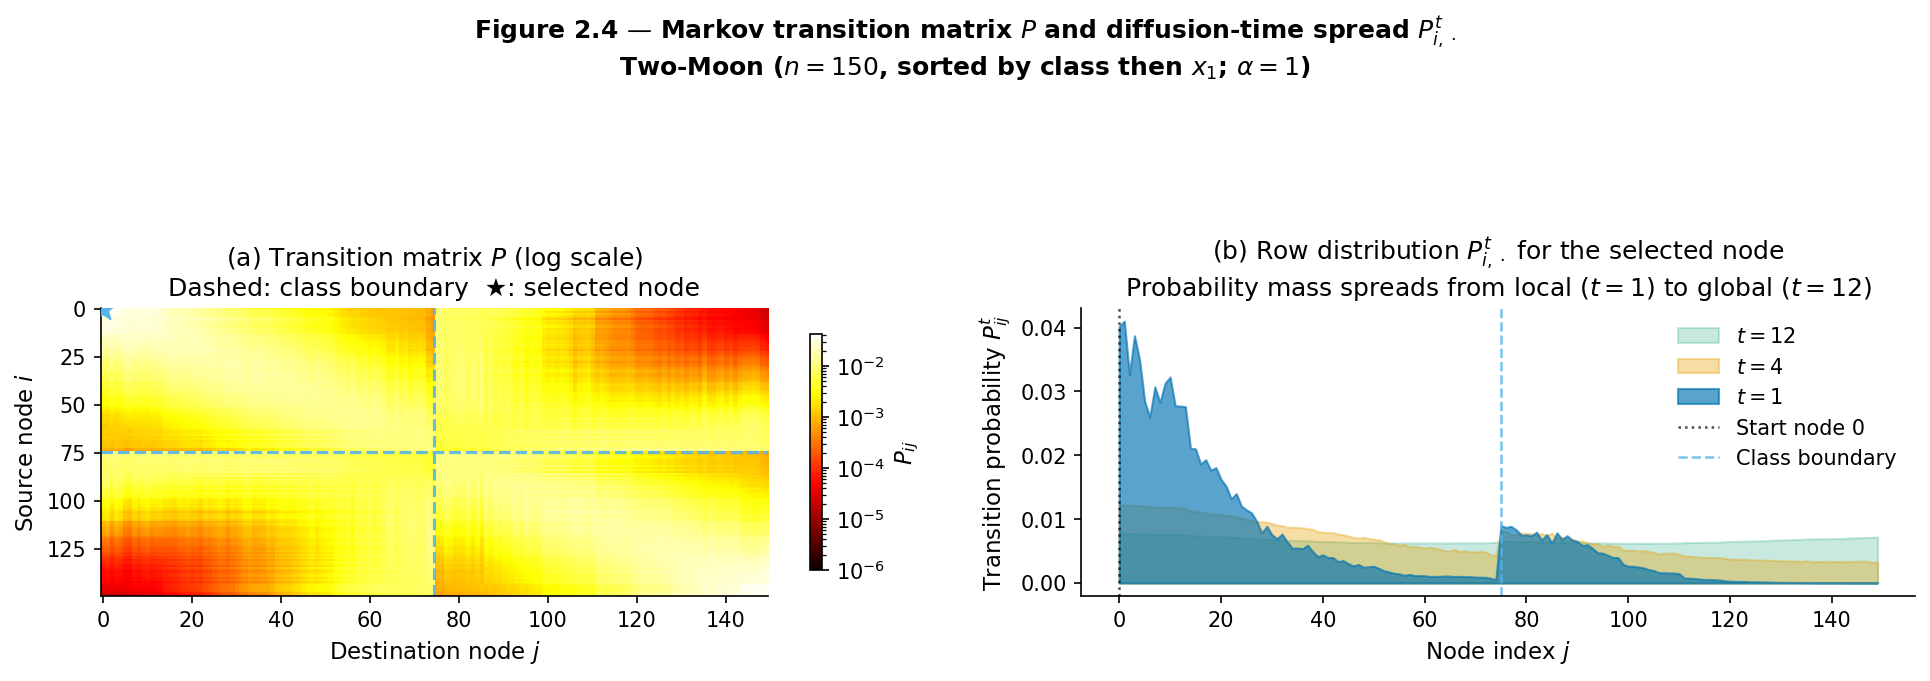

Saved: fig2_4_markov_dynamics.pdf


In [ ]:
# ── Figure 2.4 — Markov transition matrix and diffusion spread ───────────────
np.random.seed(4)
n_mk = 150
X_mk, y_mk = make_moons(n_samples=n_mk, noise=0.07, random_state=4)
# Sort by class then x1 for clean block structure in heatmap
idx_mk  = np.argsort(y_mk * 100 + X_mk[:, 0])
X_mk    = X_mk[idx_mk]
y_mk    = y_mk[idx_mk]
n_cls0  = int((y_mk == 0).sum())

_, _, P_mk, _, _, _ = build_diffusion_map(X_mk, epsilon='median', alpha=1.0,
                                          n_components=8)

# Pick a starting node near the tip of class-0 moon
node_idx = np.argmin(X_mk[y_mk == 0, 0])   # leftmost point in class 0
node_idx = np.where(y_mk == 0)[0][node_idx]

# Compute P^t rows via repeated matrix multiplication (n=150 → fast)
Pt1  = P_mk[node_idx].copy()
Pt4  = np.linalg.matrix_power(P_mk, 4)[node_idx]
Pt12 = np.linalg.matrix_power(P_mk, 12)[node_idx]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
fig.suptitle(
    r'Figure 2.4 — Markov transition matrix $P$ and diffusion-time spread $P^t_{i,\cdot}$'
    '\n' r'Two-Moon ($n = 150$, sorted by class then $x_1$; $\alpha = 1$)',
    fontsize=12, fontweight='bold')

# (a) P heatmap (log scale to reveal off-diagonal structure)
P_disp = np.clip(P_mk, 1e-8, None)
im = axes[0].imshow(P_disp, cmap='hot', aspect='auto', interpolation='nearest',
                    norm=mpl.colors.LogNorm(vmin=1e-6, vmax=P_mk.max()))
axes[0].axhline(n_cls0 - 0.5, color=CB['sky'], lw=1.5, ls='--', alpha=0.9)
axes[0].axvline(n_cls0 - 0.5, color=CB['sky'], lw=1.5, ls='--', alpha=0.9)
axes[0].scatter([node_idx], [node_idx], marker='*', s=130, c=CB['sky'], zorder=5)
axes[0].set_title('(a) Transition matrix $P$ (log scale)\n'
                  'Dashed: class boundary  ★: selected node', pad=6)
axes[0].set_xlabel('Destination node $j$')
axes[0].set_ylabel('Source node $i$')
plt.colorbar(im, ax=axes[0], shrink=0.82, label='$P_{ij}$')

# (b) Diffusion-spread row distributions
xn = np.arange(n_mk)
axes[1].fill_between(xn, Pt12, alpha=0.22, color=CB['green'],     label='$t = 12$')
axes[1].fill_between(xn, Pt4,  alpha=0.35, color=CB['orange'],    label='$t = 4$')
axes[1].fill_between(xn, Pt1,  alpha=0.65, color=CB['blue'],      label='$t = 1$')
axes[1].axvline(node_idx,  color='black',   ls=':',  lw=1.2, alpha=0.7,
                label=f'Start node {node_idx}')
axes[1].axvline(n_cls0,    color=CB['sky'], ls='--', lw=1.2, alpha=0.8,
                label='Class boundary')
axes[1].set_title('(b) Row distribution $P^t_{i,\\cdot}$ for the selected node\n'
                  'Probability mass spreads from local $(t=1)$ to global $(t=12)$',
                  pad=6)
axes[1].set_xlabel('Node index $j$')
axes[1].set_ylabel('Transition probability $P^t_{ij}$')
axes[1].legend(frameon=False, loc='upper right')

plt.tight_layout(rect=[0, 0, 1, 0.83])
fig.savefig('pictures/fig2_4_markov_dynamics.pdf', dpi=300, bbox_inches='tight')
plt.show()
print("Saved: fig2_4_markov_dynamics.pdf")

---
## §2.4 Spectral Decomposition and Diffusion Coordinates

Let $(\lambda_\ell, \psi_\ell)$ be the right eigenpairs of $P$:

$$
P\,\psi_\ell = \lambda_\ell\,\psi_\ell, \qquad 1 = \lambda_0 \geq \lambda_1 \geq \lambda_2 \geq \cdots \geq 0.
$$

Because $P$ is a similarity transformation of the symmetric matrix $A = D^{-1/2}\widetilde{W}D^{-1/2}$, it has real eigenvalues in $[0,1]$.  The trivial mode $\lambda_0 = 1$ corresponds to the stationary distribution and carries no discriminative information.  All structural information resides in the **non-trivial eigenvectors** $\psi_1, \psi_2, \dots$

The **diffusion coordinates** at diffusion time $t$ are:

$$
\Psi_t(x_i) = \bigl(\lambda_1^t\,\psi_1(i),\;\lambda_2^t\,\psi_2(i),\;\dots,\;\lambda_m^t\,\psi_m(i)\bigr) \in \mathbb{R}^m.
$$

The powers $\lambda_\ell^t$ act as a **spectral filter**:
- Eigenvalues close to 1 (slow-decaying modes) encode large-scale manifold structure.
- Eigenvalues near 0 decay rapidly with $t$, suppressing high-frequency noise components.
- A **spectral gap** after the first $m$ eigenvalues signals an intrinsic dimensionality of $m$.

A practical benefit is that changing $t$ only requires rescaling the existing eigenvectors — no recomputation of the eigendecomposition.  **Figure 2.5** shows the eigenvalue spectrum and the resulting two-dimensional diffusion embedding on the Swiss Roll.

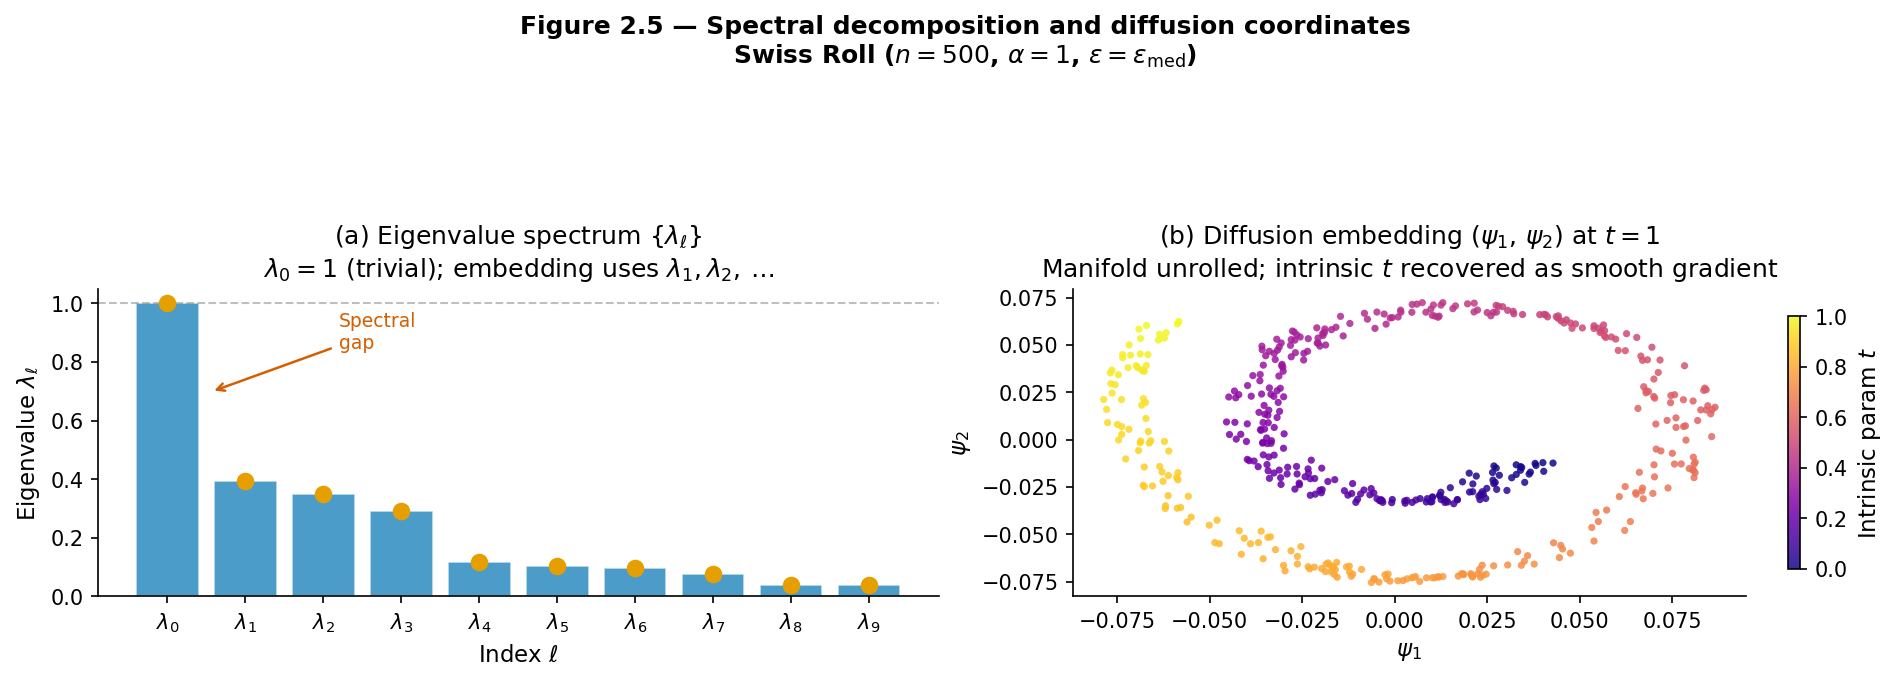

Saved: fig2_5_spectral_embedding.pdf


In [ ]:
# ── Figure 2.5 — Eigenvalue spectrum and 2-D diffusion embedding ─────────────
np.random.seed(5)
n_emb  = 500
X_emb, t_emb = make_swiss_roll(n_samples=n_emb, noise=0.10, random_state=5)
t_emb_n = (t_emb - t_emb.min()) / (t_emb.max() - t_emb.min())

vals_e, psi_e, _, _, _, _ = build_diffusion_map(
    X_emb, epsilon='median', alpha=1.0, n_components=10)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
fig.suptitle(
    r'Figure 2.5 — Spectral decomposition and diffusion coordinates'
    '\n' r'Swiss Roll ($n = 500$, $\alpha = 1$, $\varepsilon = \varepsilon_{\rm med}$)',
    fontsize=12, fontweight='bold')

# (a) Eigenvalue spectrum
k_show  = 10
indices = np.arange(k_show)
axes[0].bar(indices, vals_e[:k_show],
            color=CB['blue'], alpha=0.70, edgecolor='white', linewidth=0.8)
axes[0].scatter(indices, vals_e[:k_show],
                color=CB['orange'], s=55, zorder=5)
axes[0].axhline(1.0, color='grey', ls='--', lw=1.0, alpha=0.5)

# Annotate spectral gap (largest drop after trivial mode)
gaps  = -np.diff(vals_e[:k_show])
g_idx = int(np.argmax(gaps))
y_mid = float((vals_e[g_idx] + vals_e[g_idx + 1]) / 2)
axes[0].annotate(
    'Spectral\ngap',
    xy=(g_idx + 0.55, y_mid),
    xytext=(g_idx + 2.2, y_mid + 0.15),
    fontsize=9, color=CB['vermilion'],
    arrowprops=dict(arrowstyle='->', color=CB['vermilion'], lw=1.2))
axes[0].set_title(r'(a) Eigenvalue spectrum $\{\lambda_\ell\}$'
                  '\n' r'$\lambda_0 = 1$ (trivial); embedding uses $\lambda_1, \lambda_2, \dots$',
                  pad=6)
axes[0].set_xlabel(r'Index $\ell$')
axes[0].set_ylabel(r'Eigenvalue $\lambda_\ell$')
axes[0].set_xticks(indices)
axes[0].set_xticklabels([f'$\\lambda_{{{i}}}$' for i in indices])

# (b) 2-D diffusion embedding (ψ₁ vs ψ₂, coloured by intrinsic t)
sc = axes[1].scatter(psi_e[:, 1], psi_e[:, 2],
                     c=t_emb_n, cmap='plasma', s=12, alpha=0.85, linewidths=0)
axes[1].set_title(r'(b) Diffusion embedding $(\psi_1,\,\psi_2)$ at $t = 1$'
                  '\nManifold unrolled; intrinsic $t$ recovered as smooth gradient',
                  pad=6)
axes[1].set_xlabel(r'$\psi_1$')
axes[1].set_ylabel(r'$\psi_2$')
fig.colorbar(sc, ax=axes[1], shrink=0.82, label='Intrinsic param $t$')

plt.tight_layout(rect=[0, 0, 1, 0.83])
fig.savefig('pictures/fig2_5_spectral_embedding.pdf', dpi=300, bbox_inches='tight')
plt.show()
print("Saved: fig2_5_spectral_embedding.pdf")

---
## §2.5 Diffusion Distance and Its Interpretation

The **diffusion distance** at time $t$ between nodes $i$ and $j$ is defined as

$$
D_t^2(i, j) = \sum_{k=1}^{n} \frac{\bigl(P^t_{ik} - P^t_{jk}\bigr)^2}{\pi_k},
$$

where $\pi$ is the stationary distribution of the random walk.  Two points are *close in diffusion distance* when their $t$-step transition **distributions over all nodes** are similar — that is, they reach the same regions of the manifold with similar probability.

This criterion is often stronger than Euclidean proximity:

| Scenario | Euclidean distance | Diffusion distance | Manifold relationship |
|---|---|---|---|
| Two points on opposite arms of Two-Moon, near the boundary | **small** | **large** | Different manifold regions |
| Two points on the same moon arm, far apart | **large** | **small** | Same manifold region, connected via diffusion paths |

Using the spectral expansion, the diffusion distance is efficiently approximated by

$$
D_t^2(i, j) \approx \sum_{\ell=1}^{m} \lambda_\ell^{2t}\,\bigl(\psi_\ell(i) - \psi_\ell(j)\bigr)^2,
$$

which corresponds to **squared Euclidean distance** in the scaled diffusion coordinate space $\{\lambda_\ell^t \psi_\ell\}$.  This supports using standard Euclidean algorithms (clustering, regression) directly in the diffusion embedding, with approximation mainly controlled by the truncation level $m$.  **Figure 2.6** illustrates how diffusion distance separates the two classes of Two-Moon more cleanly than Euclidean distance.

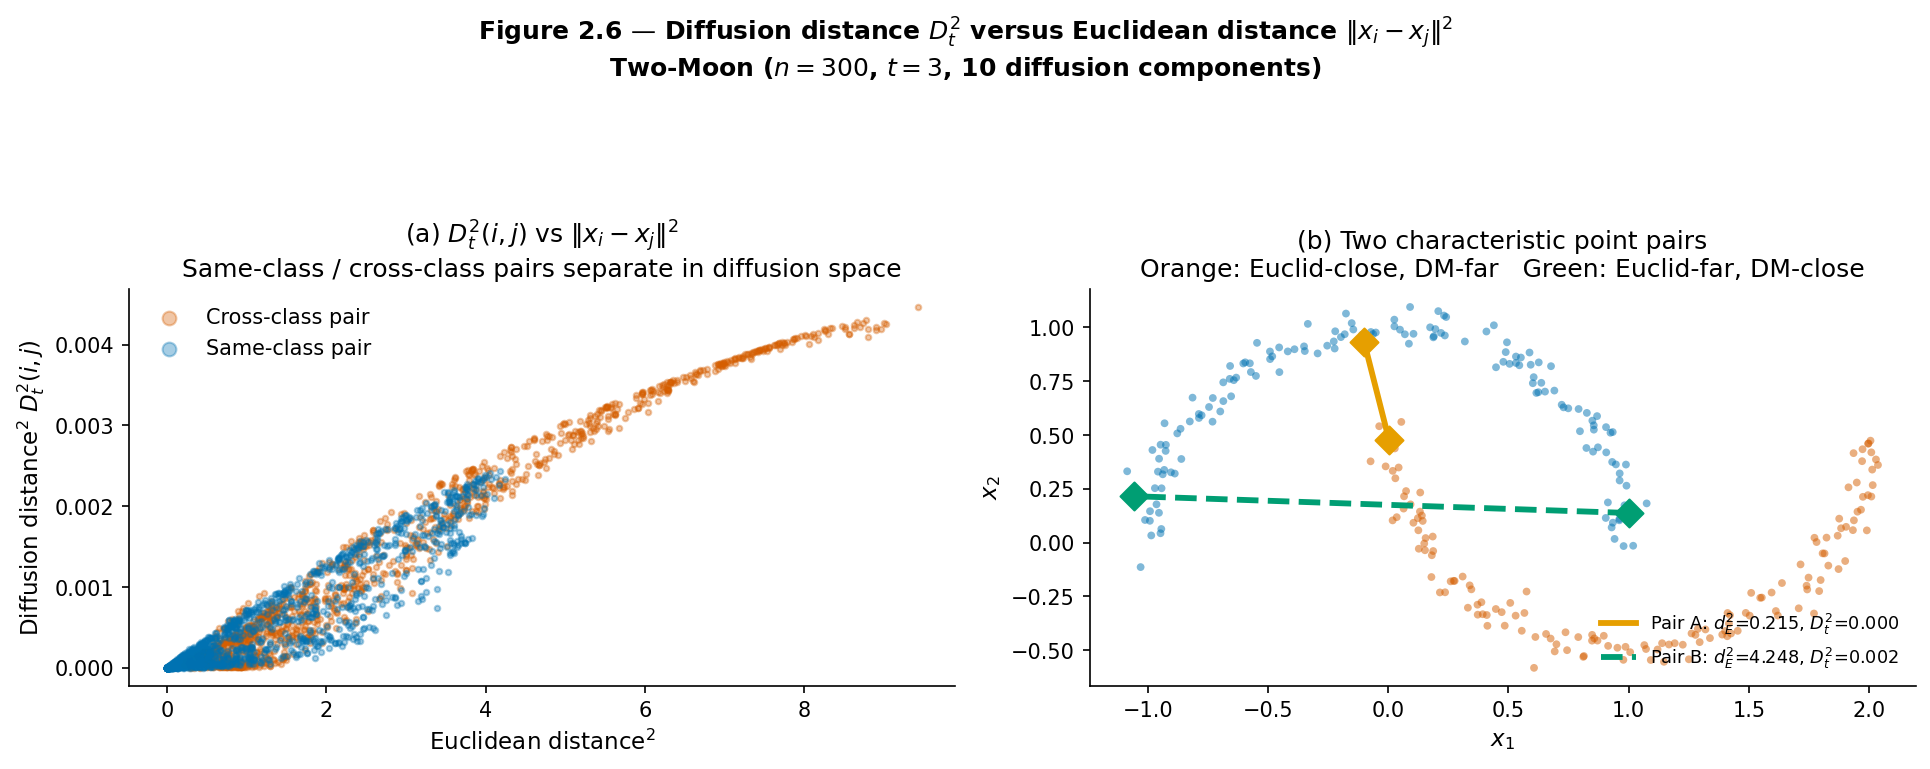

Saved: fig2_6_diffusion_distance.pdf


In [ ]:
# ── Figure 2.6 — Diffusion distance vs Euclidean distance ───────────────────
np.random.seed(6)
n_dd = 300
X_dd, y_dd = make_moons(n_samples=n_dd, noise=0.05, random_state=6)

vals_dd, psi_dd, _, _, _, _ = build_diffusion_map(
    X_dd, epsilon='median', alpha=1.0, n_components=15)

# Spectral diffusion distance²: D_t²(i,j) = Σ_{l≥1} λ_l^{2t} (ψ_l(i)-ψ_l(j))²
t_diff    = 3
n_use     = 10   # non-trivial components
lam_2t    = vals_dd[1:n_use + 1] ** (2 * t_diff)
psi_sc    = psi_dd[:, 1:n_use + 1] * np.sqrt(lam_2t)[None, :]
D_diff    = cdist(psi_sc, psi_sc, 'sqeuclidean')
D_euc     = cdist(X_dd,  X_dd,  'sqeuclidean')

# Sample random pairs (i != j)
rng    = np.random.default_rng(42)
i_idx  = rng.integers(0, n_dd, 3000)
j_idx  = rng.integers(0, n_dd, 3000)
valid  = i_idx != j_idx
i_idx, j_idx = i_idx[valid][:2500], j_idx[valid][:2500]
same   = y_dd[i_idx] == y_dd[j_idx]

euc_v  = D_euc[i_idx, j_idx]
dif_v  = D_diff[i_idx, j_idx]

# Find extreme pairs for annotation
cross_idx = np.where(~same)[0]
same_idx  = np.where(same)[0]
pA = cross_idx[np.argmin(euc_v[cross_idx])]
iA, jA = int(i_idx[pA]), int(j_idx[pA])
pB = same_idx[np.argmax(euc_v[same_idx])]
iB, jB = int(i_idx[pB]), int(j_idx[pB])

fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
fig.suptitle(
    r'Figure 2.6 — Diffusion distance $D_t^2$ versus Euclidean distance $\|x_i - x_j\|^2$'
    f'\nTwo-Moon ($n = {n_dd}$, $t = {t_diff}$, {n_use} diffusion components)',
    fontsize=12, fontweight='bold')

# (a) Scatter coloured by class relationship
axes[0].scatter(euc_v[~same], dif_v[~same],
                c=CB['vermilion'], s=7, alpha=0.35, label='Cross-class pair')
axes[0].scatter(euc_v[same], dif_v[same],
                c=CB['blue'],     s=7, alpha=0.35, label='Same-class pair')
axes[0].set_title(r'(a) $D_t^2(i,j)$ vs $\|x_i - x_j\|^2$'
                  '\nSame-class / cross-class pairs separate in diffusion space',
                  pad=6)
axes[0].set_xlabel(r'Euclidean distance$^2$')
axes[0].set_ylabel(r'Diffusion distance$^2$ $D_t^2(i,j)$')
axes[0].legend(frameon=False, markerscale=2.5)

# (b) Data with the two highlighted pairs
cls_col = [CB['blue'] if c == 0 else CB['vermilion'] for c in y_dd]
axes[1].scatter(X_dd[:, 0], X_dd[:, 1],
                c=cls_col, s=14, alpha=0.50, linewidths=0, zorder=2)
# Pair A (orange): Euclidean-close, diffusion-far
axes[1].plot([X_dd[iA, 0], X_dd[jA, 0]], [X_dd[iA, 1], X_dd[jA, 1]],
             color=CB['orange'], lw=2.8, zorder=4,
             label=f'Pair A: $d_E^2$={euc_v[pA]:.3f}, $D_t^2$={dif_v[pA]:.3f}')
axes[1].scatter([X_dd[iA, 0], X_dd[jA, 0]], [X_dd[iA, 1], X_dd[jA, 1]],
                color=CB['orange'], s=90, zorder=5, marker='D')
# Pair B (green): Euclidean-far, diffusion-close
axes[1].plot([X_dd[iB, 0], X_dd[jB, 0]], [X_dd[iB, 1], X_dd[jB, 1]],
             color=CB['green'], lw=2.8, zorder=4, ls='--',
             label=f'Pair B: $d_E^2$={euc_v[pB]:.3f}, $D_t^2$={dif_v[pB]:.3f}')
axes[1].scatter([X_dd[iB, 0], X_dd[jB, 0]], [X_dd[iB, 1], X_dd[jB, 1]],
                color=CB['green'], s=90, zorder=5, marker='D')
axes[1].set_title('(b) Two characteristic point pairs\n'
                  'Orange: Euclid-close, DM-far   Green: Euclid-far, DM-close',
                  pad=6)
axes[1].set_xlabel('$x_1$')
axes[1].set_ylabel('$x_2$')
axes[1].legend(frameon=False, fontsize=8.5, loc='lower right')

plt.tight_layout(rect=[0, 0, 1, 0.87])
fig.savefig('pictures/fig2_6_diffusion_distance.pdf', dpi=300, bbox_inches='tight')
plt.show()
print("Saved: fig2_6_diffusion_distance.pdf")

---
## §2.6 Connection to Continuous Operators

Under regular sampling and appropriate scaling of $\varepsilon$ with $n$, normalised graph operators converge to **differential operators on the underlying manifold** $\mathcal{M}$.  Specifically, as $n \to \infty$ and $\varepsilon \to 0$ at appropriate rates, the normalised diffusion operator converges to the **Laplace–Beltrami operator** on $\mathcal{M}$:

$$
\frac{I - P}{\varepsilon} \;\xrightarrow{n \to \infty}\; \Delta_{\mathcal{M}},
$$

where $\Delta_{\mathcal{M}}$ is the intrinsic Laplacian on the manifold.  The eigenfunctions of $\Delta_{\mathcal{M}}$ are the continuous limits of the discrete eigenvectors $\psi_\ell$.

This continuum limit provides two key theoretical motivations:

1. **Intrinsic coordinate recovery tendency** — Under standard regularity assumptions, Diffusion Map eigenvectors approximate manifold coordinates rather than arbitrary graph artefacts.
2. **Noise robustness tendency** — Because the Laplacian smooths high-frequency perturbations, the embedding tends to remain stable under small additive noise in $\mathcal{X}$, provided $\varepsilon$ is chosen sensibly relative to the noise scale.

With $\alpha = 1$, the limit operator is the Laplace–Beltrami operator intrinsic to $\mathcal{M}$ — independent of the sampling density.  For $\alpha = 0$, the limit is instead the Fokker–Planck operator, which depends on the density and is appropriate for different applications.

---
## §2.7 Role of Hyperparameters in Theory

Theoretical behaviour is governed by four coupled design choices:

| Parameter | Symbol | Effect |
|---|---|---|
| Kernel bandwidth | $\varepsilon$ | Sets neighbourhood radius; controls local–global trade-off in graph connectivity |
| Density correction | $\alpha$ | $\alpha=0$: raw graph; $\alpha=1$: geometry-preserving, density-independent Laplacian |
| Diffusion time | $t$ | Smaller $t$: fine local detail; larger $t$: smooth global structure; governs noise suppression |
| Embedding dimension | $m$ | Truncates spectral representation; should be chosen at or just before a spectral gap |

A practical selection principle: choose $\varepsilon$ so that the graph is **connected** and each point has a moderate effective number of neighbours; choose $m$ at the **spectral gap**; and adjust $t$ to balance local fidelity against noise suppression.

**Figure 2.7** provides a representative comparison: PCA on Swiss Roll versus Diffusion Map, both coloured by the intrinsic parameter $t$.  PCA projects onto linear variance directions and entangles the roll, while Diffusion Map unrolls the manifold more clearly and recovers intrinsic structure as a smooth gradient in $(\psi_1, \psi_2)$ space.

> **Chapter summary** — This chapter formalised the four-step Diffusion Map pipeline (affinity graph → anisotropic normalisation → Markov operator → spectral embedding), established the connection to the Laplace–Beltrami operator, and demonstrated each theoretical component through figures on synthetic manifold data.  Chapter 3 translates these theoretical choices into a reproducible implementation and hyperparameter strategy.

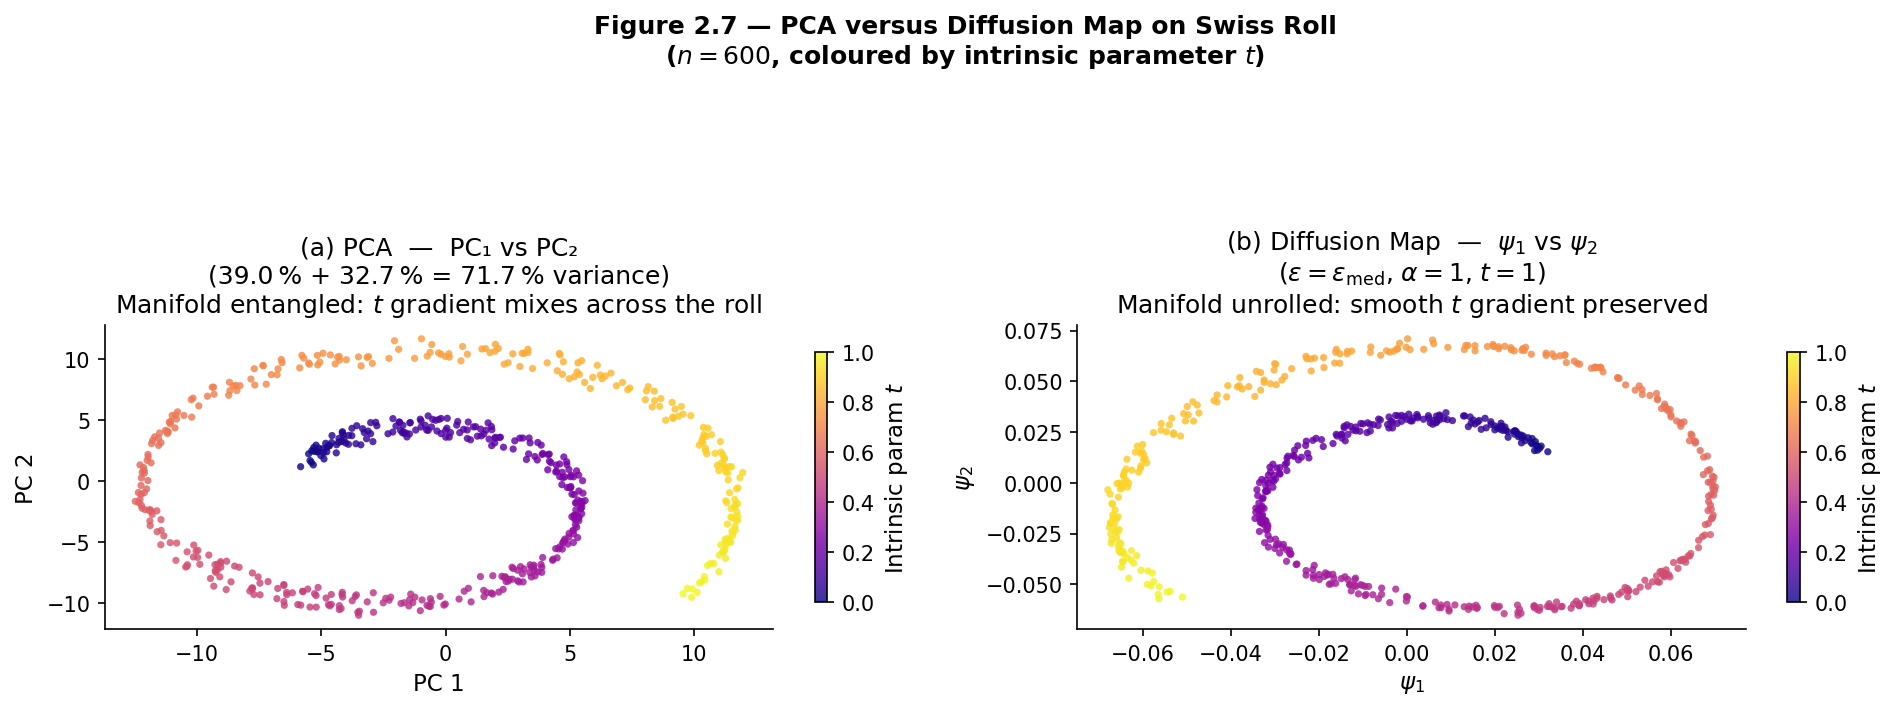

Saved: fig2_7_pca_vs_diffusion.pdf


In [ ]:
# ── Figure 2.7 — PCA vs Diffusion Map on Swiss Roll ─────────────────────────
np.random.seed(7)
n_cmp = 600
X_cmp, t_cmp = make_swiss_roll(n_samples=n_cmp, noise=0.12, random_state=7)
t_cmp_n = (t_cmp - t_cmp.min()) / (t_cmp.max() - t_cmp.min())

# PCA reduction to 2D
pca      = PCA(n_components=2)
X_pca    = pca.fit_transform(X_cmp)
pca_var  = pca.explained_variance_ratio_

# Diffusion Map reduction to 2D
vals_c, psi_c, _, _, _, _ = build_diffusion_map(
    X_cmp, epsilon='median', alpha=1.0, n_components=6)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
fig.suptitle(
    'Figure 2.7 — PCA versus Diffusion Map on Swiss Roll\n'
    r'($n = 600$, coloured by intrinsic parameter $t$)',
    fontsize=12, fontweight='bold')

# (a) PCA
sc1 = axes[0].scatter(X_pca[:, 0], X_pca[:, 1],
                      c=t_cmp_n, cmap='plasma', s=12, alpha=0.82, linewidths=0)
axes[0].set_title(
    '(a) PCA  —  PC₁ vs PC₂\n'
    f'({100*pca_var[0]:.1f}\u202f% + {100*pca_var[1]:.1f}\u202f%'
    f' = {100*sum(pca_var[:2]):.1f}\u202f% variance)\n'
    'Manifold remains entangled: $t$ gradient mixes across the roll',
    pad=6)
axes[0].set_xlabel('PC 1')
axes[0].set_ylabel('PC 2')
fig.colorbar(sc1, ax=axes[0], shrink=0.82, label='Intrinsic param $t$')

# (b) Diffusion Map
sc2 = axes[1].scatter(psi_c[:, 1], psi_c[:, 2],
                      c=t_cmp_n, cmap='plasma', s=12, alpha=0.82, linewidths=0)
axes[1].set_title(
    r'(b) Diffusion Map  —  $\psi_1$ vs $\psi_2$'
    '\n' r'($\varepsilon = \varepsilon_{\rm med}$, $\alpha = 1$, $t = 1$)'
    '\nManifold is more clearly unrolled: smoother $t$ gradient is preserved',
    pad=6)
axes[1].set_xlabel(r'$\psi_1$')
axes[1].set_ylabel(r'$\psi_2$')
fig.colorbar(sc2, ax=axes[1], shrink=0.82, label='Intrinsic param $t$')

plt.tight_layout(rect=[0, 0, 1, 0.83])
fig.savefig('pictures/fig2_7_pca_vs_diffusion.pdf', dpi=300, bbox_inches='tight')
plt.show()
print("Saved: fig2_7_pca_vs_diffusion.pdf")